# Classification de textes arabes avec des modèles séquentiels

**Partie 1 : tâche de classification**


## Objectif

Dans le premier notebook, on a collecté des textes arabes sur l'éducation au Maroc et on leur a donné un score de pertinence entre 0 et 10. Ici on utilise ce dataset pour entraîner quatre modèles : RNN, Bidirectional RNN, GRU et LSTM. Le but est de comparer leurs résultats et de voir lequel marche le mieux.

## Plan

1. Configuration
2. Chargement et exploration du dataset
3. Discrétisation du score en classes de pertinence
4. Pipeline de prétraitement NLP (nettoyage, normalisation, tokenisation, mots vides, racinisation, lemmatisation)
5. Découpage entraînement / validation / test (par article)
6. Vocabulaire, encodage et DataLoaders
7. Architectures des modèles
8. Fonctions d'entraînement et d'évaluation
9. Réglage des hyperparamètres
10. Évaluation finale sur le jeu de test
11. Courbes d'apprentissage et analyse
12. Sauvegarde des résultats et bilan

## 1. Configuration

### 1.1 Installation

On installe `qalsadi` (pour la lemmatisation en arabe) et `seaborn` (pour les graphiques). Le reste est déjà installé sur Colab.

In [2]:
!pip -q install qalsadi seaborn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


### 1.2 Importation des bibliothèques

On importe les outils de manipulation de données, de prétraitement du texte (NLTK), de modélisation (PyTorch) et d'évaluation (scikit-learn).

In [1]:
import os, re, json, random, time, copy
from collections import Counter
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

import nltk
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             mean_absolute_error)

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")
print("PyTorch :", torch.__version__)

PyTorch : 2.14.1+cu130


### 1.3 Reproductibilité et matériel

On fixe les graines aléatoires afin que les résultats soient reproductibles, puis on sélectionne le GPU  .

In [3]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Périphérique utilisé :", device)

Périphérique utilisé : cuda


### 1.4 Chemins des fichiers

On monte Google Drive pour retrouver le dataset du premier notebook. Les résultats de ce notebook (modèles, tableaux, vocabulaire) sont enregistrés dans le dossier `resultats_partie1`.

In [4]:
IN_COLAB = "google.colab" in str(get_ipython())

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/Projet_NLP_Education_Maroc/"
else:
    DATA_DIR = "./"

DATA_FILE = os.path.join(DATA_DIR, "dataset_education_maroc_full.csv")
OUT_DIR = os.path.join(DATA_DIR, "resultats_partie1")
os.makedirs(OUT_DIR, exist_ok=True)

print("Fichier de données :", DATA_FILE)
print("Dossier des résultats :", OUT_DIR)

Mounted at /content/drive
Fichier de données : /content/drive/MyDrive/Projet_NLP_Education_Maroc/dataset_education_maroc_full.csv
Dossier des résultats : /content/drive/MyDrive/Projet_NLP_Education_Maroc/resultats_partie1


## 2. Chargement et exploration du dataset

On charge le fichier `dataset_education_maroc_full.csv`. Il contient le texte, le score, l'article d'origine (`article_id`) et la source. Le `article_id` ne sert pas comme entrée du modèle : on l'utilise plus tard pour séparer les données par article.

In [5]:
df = pd.read_csv(DATA_FILE, encoding="utf-8-sig")

print("Dimensions :", df.shape)
print("Valeurs manquantes :\n", df.isna().sum(), sep="")
print("Textes dupliqués :", df["Text"].duplicated().sum())

display(df.head())

Dimensions : (342, 4)
Valeurs manquantes :
Text          0
Score         0
article_id    0
source        0
dtype: int64
Textes dupliqués : 0


,Text,Score,article_id,source
0,جامعة محمد الخامس هي جامعة مغربية تأسست سنة 1957 بموجب ظهير ملكي شريف، تقع وسط العاصمة المغربية الرباط، وتعد ثاني أق...,8.0,WIKI_52969,Wikipédia arabe
1,له 180 مليون درهم لبنائه. والذي تم افتتاحه في يناير من سنة 2022. == نصوص قانونية == مرسوم رقم 2.90.554 صادر في 2 رجب...,7.5,WIKI_52969,Wikipédia arabe
2,وزيادة عدد الطلبة والبرامج الأكاديمية، بالإضافة لتطور البنية التحتية الجامعية، بما في ذلك المرافق البحثية والمختبرات...,8.0,WIKI_52969,Wikipédia arabe
3,حيث جاءت ضمن فئة 1001-1200 عالميًا، مع تسجيل 70.1 من 100 في مؤشر فرص العمل للخريجين، نتيجة الجهود المبذولة لتحسين مه...,8.0,WIKI_52969,Wikipédia arabe
4,معهد الدراسات الأفريقية‘ معهد الدراسات الإسبانية البرتغالية معهد الدراسات والأبحاث للتعريب‘ === العلوم القانونية وال...,8.0,WIKI_52969,Wikipédia arabe


### 2.1 Scores et longueur des textes

On trace la distribution des scores et du nombre de mots par texte. Le dataset contient 342 textes. La plupart ont 120 mots, car on les a découpés comme ça dans le premier notebook. Les scores sont surtout dans la partie haute (médiane 7,5).

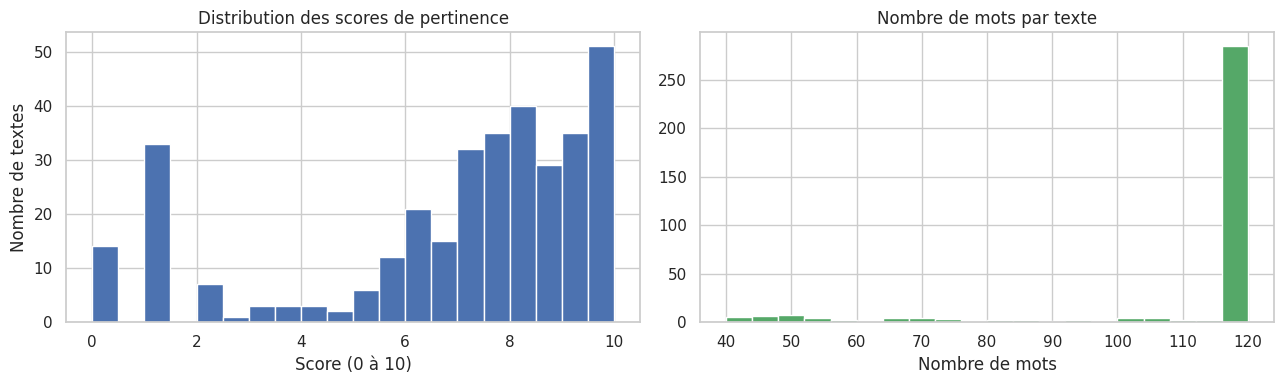

        Score  n_words
count  342.00   342.00
mean     6.64   111.78
std      2.89    20.73
min      0.00    40.00
25%      6.00   120.00
50%      7.50   120.00
75%      8.88   120.00
max     10.00   120.00

Répartition par source :
source
Wikipédia arabe                                                        262
Revue Marocaine de Publication des Recherches Scientifiques (RMPRS)     80
Name: count, dtype: int64


In [7]:
df["n_words"] = df["Text"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df["Score"], bins=20, color="#4C72B0", edgecolor="white")
axes[0].set_title("Distribution des scores de pertinence")
axes[0].set_xlabel("Score (0 à 10)")
axes[0].set_ylabel("Nombre de textes")

axes[1].hist(df["n_words"], bins=20, color="#55A868", edgecolor="white")
axes[1].set_title("Nombre de mots par texte")
axes[1].set_xlabel("Nombre de mots")

plt.tight_layout()
plt.show()

print(df[["Score", "n_words"]].describe().round(2))
print("\nRépartition par source :")
print(df["source"].value_counts())

## 3. Transformation du score en classes

Le TP demande une tâche de **classification**, alors que notre score est un nombre entre 0 et 10. On le transforme donc en 3 classes :

| Classe | Scores | Sens |
|---|---|---|
| 0 : faible | 0 à 5,5 | peu lié au sujet |
| 1 : moyenne | 6 à 7,5 | lié au sujet de façon indirecte |
| 2 : forte | 8 à 10 | directement sur l'éducation au Maroc |

Les seuils sont dans la variable `BINS`, donc on peut les changer facilement. On obtient 84 textes faibles, 103 moyens et 155 forts : les classes ne sont pas parfaitement équilibrées, on en tiendra compte plus tard avec des poids.

,classe,effectif,proportion (%)
0,faible,84,24.6
1,moyenne,103,30.1
2,forte,155,45.3


/tmp/ipykernel_1783/3163824752.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=CLASS_NAMES, y=counts.values, palette="viridis")


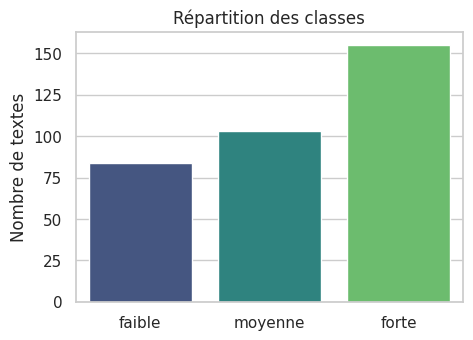

In [8]:
BINS = [-0.01, 5.5, 7.5, 10.0]
CLASS_NAMES = ["faible", "moyenne", "forte"]
NUM_CLASSES = len(CLASS_NAMES)

df["label"] = pd.cut(df["Score"], bins=BINS, labels=False).astype(int)

counts = df["label"].value_counts().sort_index()
summary = pd.DataFrame({
    "classe": CLASS_NAMES,
    "effectif": counts.values,
    "proportion (%)": (counts.values / len(df) * 100).round(1),
})
display(summary)

plt.figure(figsize=(5, 3.5))
sns.barplot(x=CLASS_NAMES, y=counts.values, palette="viridis")
plt.title("Répartition des classes")
plt.ylabel("Nombre de textes")
plt.show()

## 4. Prétraitement NLP

Les étapes du prétraitement sont :

1. **Nettoyage** : on enlève les chiffres, la ponctuation, les lettres latines, les voyelles (diacritiques) et le tatwil.
2. **Tokenisation** : on découpe le texte en mots.
3. **Mots vides** : on enlève les mots très fréquents qui n'apportent pas de sens (comme « في », « من »...).
4. **Stemming** : on garde seulement la racine ou le radical du mot. On teste deux méthodes : Snowball (léger) et ISRI (racine).
5. **Lemmatisation** : on ramène le mot à sa forme de base avec `qalsadi`.
6. **Normalisation** : on unifie certaines lettres (les différents « ا », « ى » et « ي », « ة » et « ه »).

À la fin, on a 4 versions de chaque texte : `tokens`, `stem_light`, `stem_root` et `lemma`. La variable `PREPROC_MODE` permet de choisir laquelle on donne aux modèles.

### 4.1 Nettoyage et normalisation

Pour le nettoyage, on garde uniquement les lettres arabes. La normalisation des lettres est faite à la fin, parce que le stemmer et le lemmatiseur marchent mieux sur les mots originaux.

In [9]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
DIACRITICS_RE = re.compile(r"[\u0617-\u061A\u064B-\u0652\u0670]")   # voyelles brèves, chadda, soukoun...
INVISIBLE_RE = re.compile(r"[\u200b-\u200f\u202a-\u202e]")           # marqueurs de direction
NON_ARABIC_RE = re.compile(r"[^\u0621-\u064A\s]")                    # tout sauf lettres arabes et espaces
TATWEEL = "\u0640"

def clean_text(text):
    """Nettoyage : ne garde que les lettres arabes, sans diacritiques ni tatwil."""
    text = URL_RE.sub(" ", str(text))
    text = INVISIBLE_RE.sub("", text)
    text = DIACRITICS_RE.sub("", text)
    text = text.replace(TATWEEL, "")
    text = NON_ARABIC_RE.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()

def normalize_arabic(text):
    """Unifie les variantes orthographiques : alif, ya, ta marbuta."""
    text = re.sub("[إأآٱ]", "ا", text)
    text = text.replace("ى", "ي").replace("ة", "ه")
    return text

# Exemple sur un texte du dataset
sample_text = df["Text"].iloc[0]
print("AVANT :\n", sample_text[:250])
print("\nAPRÈS NETTOYAGE :\n", clean_text(sample_text)[:250])

AVANT :
 جامعة محمد الخامس هي جامعة مغربية تأسست سنة 1957 بموجب ظهير ملكي شريف، تقع وسط العاصمة المغربية الرباط، وتعد ثاني أقدم الجامعات الحديثة بالمغرب بعد جامعة القرويين، سميت بهذا الاسم نسبة للملك المغربي الراحل محمد الخامس. في سنة 1993 وأمام تعدد الكليات 

APRÈS NETTOYAGE :
 جامعة محمد الخامس هي جامعة مغربية تأسست سنة بموجب ظهير ملكي شريف تقع وسط العاصمة المغربية الرباط وتعد ثاني أقدم الجامعات الحديثة بالمغرب بعد جامعة القرويين سميت بهذا الاسم نسبة للملك المغربي الراحل محمد الخامس في سنة وأمام تعدد الكليات والمعاهد بالعا


### 4.2 Tokenisation et mots vides

On découpe le texte nettoyé sur les espaces. Pour les mots vides, on utilise la liste arabe de NLTK (804 formes après nettoyage). On vérifie aussi qu'elle ne contient pas de mots importants pour notre sujet comme « تعليم » ou « جامعة » : ce n'est pas le cas. Sur le premier texte, on passe de 117 à 98 mots.

In [11]:
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

AR_STOP = set()
for w in stopwords.words("arabic"):
    w_clean = clean_text(w)
    if w_clean:
        AR_STOP.add(w_clean)
        AR_STOP.add(normalize_arabic(w_clean))

print("Nombre de mots vides (formes nettoyées et normalisées) :", len(AR_STOP))

# Contrôle : les termes du sujet ne doivent pas être supprimés
domain_terms = ["تعليم", "التعليم", "مدرسة", "جامعة", "الجامعة", "طالب", "طلاب",
                "أستاذ", "تربية", "المغرب", "إصلاح", "تكوين", "مدارس"]
print("Termes du sujet présents dans la liste des mots vides :",
      [t for t in domain_terms if clean_text(t) in AR_STOP or normalize_arabic(clean_text(t)) in AR_STOP])


def tokenize(text):
    return [t for t in text.split() if len(t) > 1]

def remove_stopwords(tokens):
    return [t for t in tokens if t not in AR_STOP and normalize_arabic(t) not in AR_STOP]

tokens_example = tokenize(clean_text(sample_text))
tokens_nostop_example = remove_stopwords(tokens_example)
print("\nMots avant suppression des mots vides :", len(tokens_example))
print("Mots après suppression des mots vides :", len(tokens_nostop_example))
print("Exemple :", tokens_nostop_example[:15])

Nombre de mots vides (formes nettoyées et normalisées) : 804
Termes du sujet présents dans la liste des mots vides : []

Mots avant suppression des mots vides : 117
Mots après suppression des mots vides : 98
Exemple : ['جامعة', 'محمد', 'الخامس', 'جامعة', 'مغربية', 'تأسست', 'سنة', 'بموجب', 'ظهير', 'ملكي', 'شريف', 'تقع', 'وسط', 'العاصمة', 'المغربية']


### 4.3 Stemming et lemmatisation

- **Snowball** enlève les préfixes et suffixes (ex : « المغربية » devient « مغرب »).
- **ISRI** cherche la racine du mot, donc il regroupe beaucoup plus de mots.
- **qalsadi** donne le lemme, c'est-à-dire la forme du dictionnaire.

On utilise `lru_cache` pour ne pas recalculer plusieurs fois le même mot, ce qui accélère beaucoup le traitement.

In [13]:
from nltk.stem.isri import ISRIStemmer
from nltk.stem.snowball import ArabicStemmer

isri_stemmer = ISRIStemmer()
snowball_stemmer = ArabicStemmer()

try:
    import qalsadi.lemmatizer
    qalsadi_lemmatizer = qalsadi.lemmatizer.Lemmatizer()
    LEMMA_AVAILABLE = True
    print("Lemmatiseur qalsadi disponible.")
except Exception as error:
    LEMMA_AVAILABLE = False
    print("qalsadi indisponible :", error)
    print("La lemmatisation sera remplacée par la racinisation légère.")


@lru_cache(maxsize=None)
def stem_light(word):
    try:
        return snowball_stemmer.stem(word)
    except Exception:
        return word

@lru_cache(maxsize=None)
def stem_root(word):
    try:
        return isri_stemmer.stem(word)
    except Exception:
        return word

@lru_cache(maxsize=None)
def lemmatize(word):
    if not LEMMA_AVAILABLE:
        return stem_light(word)
    try:
        lemma = qalsadi_lemmatizer.lemmatize(word)
        lemma = clean_text(lemma) if isinstance(lemma, str) else ""
        return lemma if lemma else word
    except Exception:
        return word

Lemmatiseur qalsadi disponible.


### 4.4 Comparaison sur des exemples

On regarde ce que donne chaque méthode sur quelques mots. On voit que ISRI et qalsadi ne sont pas parfaits : par exemple ISRI transforme « ملكي » en « لكي », et qalsadi transforme « تقع » en « أقعى ». Ce sont des erreurs normales pour des outils automatiques sur l'arabe.

In [14]:
words_demo = list(dict.fromkeys(tokens_nostop_example))[:20]

demo = pd.DataFrame({
    "mot": words_demo,
    "racinisation légère (Snowball)": [stem_light(w) for w in words_demo],
    "racinisation par racine (ISRI)": [stem_root(w) for w in words_demo],
    "lemmatisation (qalsadi)": [lemmatize(w) for w in words_demo],
})
display(demo)

,mot,racinisation légère (Snowball),racinisation par racine (ISRI),lemmatisation (qalsadi)
0,جامعة,جامع,جمع,جامع
1,محمد,محمد,حمد,محمد
2,الخامس,خامس,خمس,خامس
3,مغربية,مغرب,غرب,مغرب
4,تأسست,تاسس,أسس,تأسس
5,سنة,سن,سنة,سنة
6,بموجب,موجب,وجب,موجب
7,ظهير,ظهير,ظهر,ظهير
8,ملكي,ملك,لكي,ملك
9,شريف,شريف,شرف,شريف


### 4.5 Fonction de prétraitement complète

La fonction `preprocess` enchaîne toutes les étapes et renvoie les quatre représentations. La normalisation orthographique finale est appliquée à chacune d'elles.

In [15]:
def preprocess(text):
    tokens = remove_stopwords(tokenize(clean_text(text)))

    def finalize(seq):
        out = [normalize_arabic(t) for t in seq]
        return [t for t in out if len(t) > 1]

    return {
        "tokens":    finalize(tokens),
        "stem_light": finalize([stem_light(t) for t in tokens]),
        "stem_root":  finalize([stem_root(t) for t in tokens]),
        "lemma":      finalize([lemmatize(t) for t in tokens]),
    }

t0 = time.time()
processed = df["Text"].apply(preprocess)
for mode in ["tokens", "stem_light", "stem_root", "lemma"]:
    df[mode] = processed.apply(lambda d: d[mode])

print(f"Prétraitement terminé en {time.time() - t0:.1f} s")
display(df[["Text", "tokens", "lemma"]].head(3))

Prétraitement terminé en 31.3 s


,Text,tokens,lemma
0,جامعة محمد الخامس هي جامعة مغربية تأسست سنة 1957 بموجب ظهير ملكي شريف، تقع وسط العاصمة المغربية الرباط، وتعد ثاني أق...,"[جامعه, محمد, الخامس, جامعه, مغربيه, تاسست, سنه, بموجب, ظهير, ملكي, شريف, تقع, وسط, العاصمه, المغربيه, الرباط, وتعد,...","[جامع, محمد, خامس, جامع, مغرب, تاسس, سنه, موجب, ظهير, ملك, شريف, اقعي, وسط, عاصم, مغرب, رابط, تعدي, قدم, جامع, حديث,..."
1,له 180 مليون درهم لبنائه. والذي تم افتتاحه في يناير من سنة 2022. == نصوص قانونية == مرسوم رقم 2.90.554 صادر في 2 رجب...,"[مليون, لبنائه, تم, افتتاحه, سنه, نصوص, قانونيه, مرسوم, رقم, صادر, رجب, يتعلق, بالمؤسسات, الجامعيه, والاحياء, الجامع...","[مليون, بناء, تم, افتتاح, سنه, نص, قانون, مرسوم, ارقام, صادر, رجب, تعلق, مؤسس, جامع, حي, جامع, تاريخ, تاسيس, تاسس, ج..."
2,وزيادة عدد الطلبة والبرامج الأكاديمية، بالإضافة لتطور البنية التحتية الجامعية، بما في ذلك المرافق البحثية والمختبرات...,"[وزياده, عدد, الطلبه, والبرامج, الاكاديميه, بالاضافه, لتطور, البنيه, التحتيه, الجامعيه, المرافق, البحثيه, والمختبرات...","[زياده, عده, طلبه, برنامج, اكاديمي, اضافه, تطور, بن, تحت, جامع, مرفق, باحث, مختبر, سنه, انقسم, جامع, جامع, مستقل, جا..."


### 4.6 Effet sur la taille du vocabulaire

On compte les mots différents après chaque transformation. Le vocabulaire passe de 10 087 mots (texte nettoyé) à 4 130 avec la lemmatisation et à 2 990 avec ISRI. C'est utile, parce qu'avec peu de données (342 textes) un vocabulaire plus petit aide le modèle à mieux apprendre.

In [16]:
raw_tokens = df["Text"].apply(lambda t: clean_text(t).split())

stats = [{
    "représentation": "texte brut (nettoyé)",
    "mots distincts": len(set(w for seq in raw_tokens for w in seq)),
    "longueur moyenne": round(raw_tokens.str.len().mean(), 1),
}]
for mode in ["tokens", "stem_light", "stem_root", "lemma"]:
    stats.append({
        "représentation": mode,
        "mots distincts": len(set(w for seq in df[mode] for w in seq)),
        "longueur moyenne": round(df[mode].str.len().mean(), 1),
    })
display(pd.DataFrame(stats))

,représentation,mots distincts,longueur moyenne
0,texte brut (nettoyé),10087,106.5
1,tokens,9757,84.6
2,stem_light,4693,84.6
3,stem_root,2990,84.6
4,lemma,4130,84.6


### 4.7 Choix de la représentation

On choisit la lemmatisation (`lemma`) pour entraîner les modèles. On sauvegarde aussi le dataset prétraité pour pouvoir le réutiliser plus tard. Dans la suite, on pourra tester les autres représentations pour voir si elles changent les résultats.

In [17]:
PREPROC_MODE = "lemma" if LEMMA_AVAILABLE else "stem_light"
print("Représentation retenue :", PREPROC_MODE)

df["tokens_model"] = df[PREPROC_MODE]

# Sauvegarde (listes de mots converties en chaînes séparées par des espaces)
df_save = df[["Text", "Score", "label", "article_id", "source"]].copy()
for mode in ["tokens", "stem_light", "stem_root", "lemma"]:
    df_save[mode] = df[mode].apply(" ".join)
df_save.to_csv(os.path.join(OUT_DIR, "dataset_preprocessed.csv"), index=False, encoding="utf-8-sig")
print("Dataset prétraité enregistré.")

Représentation retenue : lemma
Dataset prétraité enregistré.


## 5. Séparation train / validation / test

Dans notre dataset, un même article est découpé en plusieurs passages. Si on sépare les textes au hasard, des passages du même article seront à la fois dans le train et dans le test, et le modèle aura l'air meilleur qu'il ne l'est vraiment. On sépare donc **par article** avec `GroupShuffleSplit` : 70 % pour le train, 15 % pour la validation et 15 % pour le test.

Comme il y a peu d'articles (93), on essaie 500 graines et on garde la séparation qui ressemble le plus au dataset de départ (tailles et classes). On vérifie aussi qu'aucun article n'est dans deux ensembles.

Résultat : 246 textes en train, 37 en validation et 59 en test. La validation est assez petite, il faudra s'en souvenir pour les résultats.

In [18]:
y_all = df["label"].reset_index(drop=True)
groups = df["article_id"].reset_index(drop=True)
overall_dist = np.bincount(y_all, minlength=NUM_CLASSES) / len(y_all)
target_sizes = np.array([0.70, 0.15, 0.15])

def try_split(seed):
    gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=seed)
    train_idx, tmp_idx = next(gss1.split(np.zeros(len(y_all)), y_all, groups))
    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=seed)
    v, t = next(gss2.split(np.zeros(len(tmp_idx)), y_all[tmp_idx], groups[tmp_idx]))
    return train_idx, tmp_idx[v], tmp_idx[t]

def split_cost(parts):
    cost = 0.0
    for part, target in zip(parts, target_sizes):
        dist = np.bincount(y_all[part], minlength=NUM_CLASSES) / len(part)
        if (dist == 0).any():
            return np.inf                       # une classe absente : découpage rejeté
        cost += np.abs(dist - overall_dist).sum() + 2 * abs(len(part) / len(y_all) - target)
    return cost

best_seed, best_cost = None, np.inf
for seed in range(500):
    parts = try_split(seed)
    cost = split_cost(parts)
    if cost < best_cost:
        best_seed, best_cost = seed, cost

train_idx, val_idx, test_idx = try_split(best_seed)
print("Graine retenue :", best_seed, "| coût :", round(best_cost, 3))

# Aucune fuite : aucun article en commun
assert not (set(groups[train_idx]) & set(groups[val_idx]))
assert not (set(groups[train_idx]) & set(groups[test_idx]))
assert not (set(groups[val_idx]) & set(groups[test_idx]))

report = []
for name, idx in [("entraînement", train_idx), ("validation", val_idx), ("test", test_idx)]:
    row = {"ensemble": name, "textes": len(idx), "articles": groups[idx].nunique()}
    for k, c in enumerate(CLASS_NAMES):
        row[c] = int((y_all[idx] == k).sum())
    report.append(row)
display(pd.DataFrame(report))

Graine retenue : 303 | coût : 0.437


,ensemble,textes,articles,faible,moyenne,forte
0,entraînement,246,65,58,79,109
1,validation,37,14,11,8,18
2,test,59,14,15,16,28


## 6. Vocabulaire et DataLoaders

### 6.1 Vocabulaire

On construit le vocabulaire **seulement avec le train**. Sinon, on utiliserait des informations du test. On ajoute deux mots spéciaux : `<pad>` (pour compléter les textes courts) et `<unk>` (pour les mots inconnus). Les mots qui apparaissent moins de 2 fois sont remplacés par `<unk>`. On obtient un vocabulaire de 1 947 mots.

In [19]:
MIN_FREQ = 2
PAD, UNK = "<pad>", "<unk>"

train_tokens = df["tokens_model"].iloc[train_idx]

counter = Counter(w for seq in train_tokens for w in seq)
itos = [PAD, UNK] + [w for w, c in counter.most_common() if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
VOCAB_SIZE = len(itos)

print("Mots distincts (entraînement) :", len(counter))
print("Taille du vocabulaire (fréquence >=", MIN_FREQ, ") :", VOCAB_SIZE)
print("Mots les plus fréquents :", counter.most_common(12))

Mots distincts (entraînement) : 3500
Taille du vocabulaire (fréquence >= 2 ) : 1947
Mots les plus fréquents : [('جامع', 361), ('مغرب', 325), ('تعليم', 243), ('استاذ', 175), ('وطن', 163), ('علم', 162), ('مؤسس', 148), ('مدرس', 141), ('تكوين', 133), ('عمل', 133), ('سنه', 105), ('عام', 104)]


### 6.2 Encodage

Chaque texte devient une liste de numéros (un numéro par mot). On fixe la longueur maximale à 99 mots (le 95e centile des longueurs du train) : on coupe les textes plus longs et on complète les plus courts avec `<pad>`. On garde aussi la vraie longueur de chaque texte pour que le réseau ignore le remplissage.

In [20]:
lengths_train = train_tokens.str.len()
MAX_LEN = int(np.percentile(lengths_train, 95))
print("Longueur maximale retenue :", MAX_LEN)

def encode(tokens):
    ids = [stoi.get(w, stoi[UNK]) for w in tokens][:MAX_LEN]
    length = max(len(ids), 1)                    # au moins 1 pour le packing
    ids = ids + [stoi[PAD]] * (MAX_LEN - len(ids))
    return ids, length

def make_tensors(indices):
    encoded = [encode(df["tokens_model"].iloc[i]) for i in indices]
    X = torch.tensor([e[0] for e in encoded], dtype=torch.long)
    L = torch.tensor([e[1] for e in encoded], dtype=torch.long)
    y = torch.tensor(y_all.iloc[indices].values, dtype=torch.long)
    return X, L, y

X_train, L_train, y_train = make_tensors(train_idx)
X_val,   L_val,   y_val   = make_tensors(val_idx)
X_test,  L_test,  y_test  = make_tensors(test_idx)

print("Formes :", X_train.shape, X_val.shape, X_test.shape)

Longueur maximale retenue : 99
Formes : torch.Size([246, 99]) torch.Size([37, 99]) torch.Size([59, 99])


### 6.3 DataLoaders et poids des classes

Les DataLoaders envoient les données au modèle par petits groupes (batchs). Comme les classes ne sont pas équilibrées, on calcule des poids : la classe faible (la plus rare) a un poids plus grand que la classe forte, pour que le modèle ne l'ignore pas.

In [21]:
def make_loaders(batch_size):
    train_loader = DataLoader(TensorDataset(X_train, L_train, y_train), batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(TensorDataset(X_val,   L_val,   y_val),   batch_size=128)
    test_loader  = DataLoader(TensorDataset(X_test,  L_test,  y_test),  batch_size=128)
    return train_loader, val_loader, test_loader

# Poids de classes (compense le déséquilibre éventuel des classes dans l'entraînement)
class_counts = np.bincount(y_train.numpy(), minlength=NUM_CLASSES)
class_weights = torch.tensor(len(y_train) / (NUM_CLASSES * class_counts), dtype=torch.float32).to(device)
print("Poids de classes :", class_weights.cpu().numpy().round(2))

Poids de classes : [1.41 1.04 0.75]


## 7. Architectures des modèles

Les quatre modèles partagent la même structure, seule la cellule récurrente change :

```
indices -> Embedding -> Dropout -> [RNN | GRU | LSTM] -> état caché final -> Dropout -> Linear -> 3 classes
```

| Modèle | Cellule | Sens de lecture |
|---|---|---|
| RNN | `nn.RNN` (tanh) | gauche vers droite |
| Bidirectional RNN | `nn.RNN` (tanh) | dans les deux sens |
| GRU | `nn.GRU` | gauche vers droite |
| LSTM | `nn.LSTM` | gauche vers droite |

L'**embedding** transforme chaque indice de mot en vecteur dense appris pendant l'entraînement. L'état caché final résume la séquence ; pour le modèle bidirectionnel, les états des deux sens sont concaténés. `pack_padded_sequence` permet au réseau de ne pas traiter les positions de remplissage.

In [22]:
class SequenceClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes,
                 cell="LSTM", bidirectional=False, num_layers=1, dropout=0.3, pad_idx=0):
        super().__init__()
        self.cell = cell
        self.bidirectional = bidirectional
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.embed_dropout = nn.Dropout(dropout)

        rnn_cls = {"RNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}[cell]
        self.rnn = rnn_cls(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True,
                           bidirectional=bidirectional,
                           dropout=dropout if num_layers > 1 else 0.0)

        out_dim = hidden_dim * (2 if bidirectional else 1)
        self.out_dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(out_dim, num_classes)

    def forward(self, x, lengths):
        emb = self.embed_dropout(self.embedding(x))
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.rnn(packed)
        if self.cell == "LSTM":
            hidden = hidden[0]                              # (h_n, c_n) -> h_n
        if self.bidirectional:
            features = torch.cat([hidden[-2], hidden[-1]], dim=1)   # derniers états des deux sens
        else:
            features = hidden[-1]
        return self.fc(self.out_dropout(features))


# Les quatre architectures comparées
ARCHITECTURES = {
    "RNN":    {"cell": "RNN",  "bidirectional": False},
    "BiRNN":  {"cell": "RNN",  "bidirectional": True},
    "GRU":    {"cell": "GRU",  "bidirectional": False},
    "LSTM":   {"cell": "LSTM", "bidirectional": False},
}

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Contrôle rapide : une passe avant avec chaque architecture
for name, cfg in ARCHITECTURES.items():
    m = SequenceClassifier(VOCAB_SIZE, 64, 64, NUM_CLASSES, **cfg).to(device)
    out = m(X_train[:4].to(device), L_train[:4])
    print(f"{name:6s} | sortie : {tuple(out.shape)} | paramètres : {count_parameters(m):,}")

RNN    | sortie : (4, 3) | paramètres : 133,123
BiRNN  | sortie : (4, 3) | paramètres : 141,635
GRU    | sortie : (4, 3) | paramètres : 149,763
LSTM   | sortie : (4, 3) | paramètres : 158,083


## 8. Fonctions d'entraînement

### 8.1 Une époque

La fonction `run_epoch` parcourt toutes les données une fois. Si on lui donne un optimiseur, elle entraîne le modèle ; sinon elle fait juste l'évaluation. On coupe aussi les gradients trop grands (`clip_grad_norm_`), parce que les RNN peuvent avoir des gradients qui explosent.

In [23]:
def run_epoch(model, loader, criterion, optimizer=None, clip=1.0):
    training = optimizer is not None
    model.train(training)
    total_loss, y_true, y_pred = 0.0, [], []

    with torch.set_grad_enabled(training):
        for xb, lb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb, lb)
            loss = criterion(logits, yb)

            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), clip)
                optimizer.step()

            total_loss += loss.item() * len(yb)
            y_true.extend(yb.cpu().tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().tolist())

    avg_loss = total_loss / len(y_true)
    acc = accuracy_score(y_true, y_pred)
    f1 = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)[2]
    return avg_loss, acc, f1, y_true, y_pred

### 8.2 Boucle d'entraînement avec early stopping

On utilise l'optimiseur Adam et la perte `CrossEntropyLoss` avec les poids des classes. À chaque époque, on calcule le F1 macro sur la validation et on garde le meilleur modèle. Si le F1 ne s'améliore plus pendant 8 époques, on arrête l'entraînement (*early stopping*) pour éviter le sur-apprentissage.

In [24]:
def fit(hp, arch_cfg, max_epochs=40, patience=8, verbose=False):
    """Entraîne un modèle avec les hyperparamètres hp ; renvoie le meilleur modèle et l'historique."""
    set_seed(SEED)
    train_loader, val_loader, _ = make_loaders(hp["batch_size"])

    model = SequenceClassifier(
        VOCAB_SIZE, hp["embed_dim"], hp["hidden_dim"], NUM_CLASSES,
        num_layers=hp["num_layers"], dropout=hp["dropout"], **arch_cfg
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])

    history = {"train_loss": [], "val_loss": [], "train_f1": [], "val_f1": [], "val_acc": []}
    best_f1, best_loss, best_state, best_epoch, wait = -1.0, np.inf, None, 0, 0
    start = time.time()

    for epoch in range(1, max_epochs + 1):
        tr_loss, _, tr_f1, _, _ = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, va_f1, _, _ = run_epoch(model, val_loader, criterion)

        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["train_f1"].append(tr_f1);     history["val_f1"].append(va_f1)
        history["val_acc"].append(va_acc)

        if verbose:
            print(f"Epoque {epoch:02d} | train loss {tr_loss:.3f} F1 {tr_f1:.3f} | val loss {va_loss:.3f} F1 {va_f1:.3f}")

        improved = va_f1 > best_f1 or (va_f1 == best_f1 and va_loss < best_loss)
        if improved:
            best_f1, best_loss, best_epoch, wait = va_f1, va_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    info = {"val_f1": best_f1, "val_loss": best_loss, "best_epoch": best_epoch,
            "train_time": time.time() - start}
    return model, history, info

### 8.3 Premier essai avec des hyperparamètres par défaut

Avant de chercher les meilleurs hyperparamètres, on fait un essai avec le LSTM et des valeurs normales, juste pour vérifier que tout marche. On voit que la perte d'entraînement baisse beaucoup (de 1,11 à 0,06) alors que celle de validation remonte après l'époque 13 : c'est un début de sur-apprentissage. Ce problème va revenir dans la suite.

In [25]:
DEFAULT_HP = {"embed_dim": 100, "hidden_dim": 64, "num_layers": 1, "dropout": 0.3,
              "lr": 1e-3, "weight_decay": 1e-5, "batch_size": 32}

model_test, hist_test, info_test = fit(DEFAULT_HP, ARCHITECTURES["LSTM"], verbose=True)
print("\nRésumé :", {k: round(v, 3) for k, v in info_test.items()})

Epoque 01 | train loss 1.114 F1 0.239 | val loss 1.079 F1 0.303
Epoque 02 | train loss 1.082 F1 0.297 | val loss 1.069 F1 0.338
Epoque 03 | train loss 1.069 F1 0.357 | val loss 1.064 F1 0.416
Epoque 04 | train loss 1.047 F1 0.442 | val loss 1.061 F1 0.439
Epoque 05 | train loss 1.030 F1 0.500 | val loss 1.054 F1 0.454
Epoque 06 | train loss 1.011 F1 0.577 | val loss 1.045 F1 0.477
Epoque 07 | train loss 0.997 F1 0.579 | val loss 1.032 F1 0.441
Epoque 08 | train loss 0.955 F1 0.649 | val loss 1.016 F1 0.376
Epoque 09 | train loss 0.921 F1 0.707 | val loss 1.002 F1 0.464
Epoque 10 | train loss 0.890 F1 0.723 | val loss 0.976 F1 0.502
Epoque 11 | train loss 0.830 F1 0.780 | val loss 0.937 F1 0.505
Epoque 12 | train loss 0.763 F1 0.798 | val loss 0.855 F1 0.476
Epoque 13 | train loss 0.667 F1 0.788 | val loss 0.728 F1 0.511
Epoque 14 | train loss 0.575 F1 0.821 | val loss 0.833 F1 0.486
Epoque 15 | train loss 0.503 F1 0.830 | val loss 0.754 F1 0.540
Epoque 16 | train loss 0.409 F1 0.883 | 

## 9. Réglage des hyperparamètres

### 9.1 Espace de recherche

Une **recherche aléatoire** (*random search*) est utilisée : elle explore l'espace plus efficacement qu'une grille complète pour un même budget de calcul. Chaque architecture reçoit le même nombre d'essais et le même espace de recherche, ce qui rend la comparaison équitable. Les combinaisons sont comparées sur le **F1 macro de validation** ; le jeu de test n'est jamais utilisé à cette étape.

| Hyperparamètre | Valeurs testées |
|---|---|
| `embed_dim` | 50, 100, 200 |
| `hidden_dim` | 32, 64, 128 |
| `num_layers` | 1, 2 |
| `dropout` | 0,2 ; 0,3 ; 0,5 |
| `lr` (taux d'apprentissage) | 5e-4, 1e-3, 3e-3, 5e-3 |
| `weight_decay` | 0, 1e-5, 1e-4 |
| `batch_size` | 16, 32, 64 |

In [26]:
SEARCH_SPACE = {
    "embed_dim":    [50, 100, 200],
    "hidden_dim":   [32, 64, 128],
    "num_layers":   [1, 2],
    "dropout":      [0.2, 0.3, 0.5],
    "lr":           [5e-4, 1e-3, 3e-3, 5e-3],
    "weight_decay": [0, 1e-5, 1e-4],
    "batch_size":   [16, 32, 64],
}
N_TRIALS = 12          # essais par architecture (augmenter pour une recherche plus fine)

def sample_hp(rng):
    return {k: rng.choice(v) for k, v in SEARCH_SPACE.items()}

# Mêmes combinaisons pour toutes les architectures (comparaison équitable)
rng = random.Random(SEED)
trial_hps = [sample_hp(rng) for _ in range(N_TRIALS)]
print(f"{N_TRIALS} combinaisons tirées ; exemple :", trial_hps[0])

12 combinaisons tirées ; exemple : {'embed_dim': 200, 'hidden_dim': 32, 'num_layers': 1, 'dropout': 0.5, 'lr': 0.003, 'weight_decay': 0, 'batch_size': 16}


### 9.2 Lancement de la recherche

Pour chaque modèle, on entraîne les 12 combinaisons et on garde la meilleure selon le F1 de validation. C'est rapide sur GPU (quelques secondes par essai).

In [27]:
tuning_rows = []
best = {}      # architecture -> {"model", "history", "hp", "info"}

for arch_name, arch_cfg in ARCHITECTURES.items():
    print(f"\n=== {arch_name} ===")
    for t, hp in enumerate(trial_hps, start=1):
        model, history, info = fit(hp, arch_cfg)
        tuning_rows.append({"architecture": arch_name, "essai": t, **hp,
                            "val_f1": info["val_f1"], "val_loss": info["val_loss"],
                            "best_epoch": info["best_epoch"],
                            "train_time": info["train_time"]})
        print(f"essai {t:2d}/{N_TRIALS} | val F1 = {info['val_f1']:.3f} | epoque {info['best_epoch']:2d} | {info['train_time']:.0f} s")

        if arch_name not in best or info["val_f1"] > best[arch_name]["info"]["val_f1"]:
            best[arch_name] = {"model": model, "history": history, "hp": hp, "info": info}

df_tuning = pd.DataFrame(tuning_rows)
df_tuning.to_csv(os.path.join(OUT_DIR, "tuning_results.csv"), index=False)
print("\nRecherche terminée.")


=== RNN ===
essai  1/12 | val F1 = 0.509 | epoque  4 | 2 s
essai  2/12 | val F1 = 0.285 | epoque  1 | 1 s
essai  3/12 | val F1 = 0.540 | epoque 10 | 1 s
essai  4/12 | val F1 = 0.520 | epoque  3 | 1 s
essai  5/12 | val F1 = 0.454 | epoque  1 | 1 s
essai  6/12 | val F1 = 0.389 | epoque  5 | 2 s
essai  7/12 | val F1 = 0.591 | epoque 20 | 5 s
essai  8/12 | val F1 = 0.612 | epoque 25 | 7 s
essai  9/12 | val F1 = 0.543 | epoque 13 | 2 s
essai 10/12 | val F1 = 0.453 | epoque  1 | 1 s
essai 11/12 | val F1 = 0.622 | epoque 21 | 2 s
essai 12/12 | val F1 = 0.472 | epoque 15 | 2 s

=== BiRNN ===
essai  1/12 | val F1 = 0.590 | epoque 20 | 5 s
essai  2/12 | val F1 = 0.539 | epoque 19 | 3 s
essai  3/12 | val F1 = 0.424 | epoque 32 | 2 s
essai  4/12 | val F1 = 0.572 | epoque  6 | 1 s
essai  5/12 | val F1 = 0.551 | epoque  8 | 1 s
essai  6/12 | val F1 = 0.543 | epoque 36 | 11 s
essai  7/12 | val F1 = 0.626 | epoque  4 | 3 s
essai  8/12 | val F1 = 0.459 | epoque  1 | 2 s
essai  9/12 | val F1 = 0.479 | 

### 9.3 Résultats du réglage

Le tableau présente les meilleurs hyperparamètres de chaque architecture. Le second graphique montre la dispersion du F1 de validation sur l'ensemble des essais .

,architecture,embed_dim,hidden_dim,num_layers,dropout,lr,weight_decay,batch_size,val_f1,epoque
0,RNN,50,64,2,0.2,0.003,0.00010,64,0.622,21
1,BiRNN,100,64,2,0.2,0.005,0.00010,16,0.626,4
2,GRU,200,64,1,0.2,0.005,0.00001,32,0.680,9
3,LSTM,100,32,2,0.5,0.003,0.00010,16,0.795,17


/tmp/ipykernel_1783/3885803114.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_tuning, x="architecture", y="val_f1", palette="Set2")


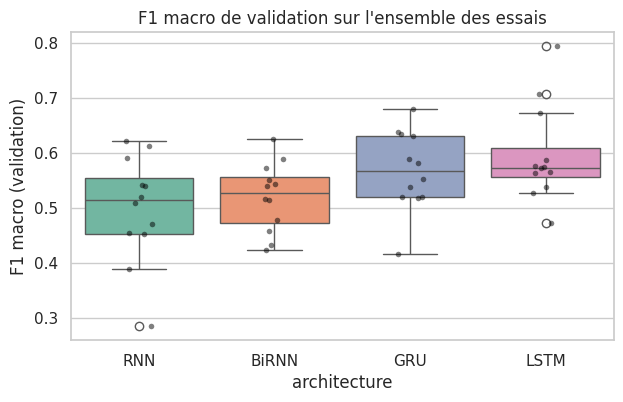

In [28]:
best_hp_table = pd.DataFrame([
    {"architecture": a, **best[a]["hp"], "val_f1": round(best[a]["info"]["val_f1"], 3),
     "epoque": best[a]["info"]["best_epoch"]}
    for a in ARCHITECTURES
])
display(best_hp_table)

plt.figure(figsize=(7, 4))
sns.boxplot(data=df_tuning, x="architecture", y="val_f1", palette="Set2")
sns.stripplot(data=df_tuning, x="architecture", y="val_f1", color="black", alpha=0.5, size=4)
plt.title("F1 macro de validation sur l'ensemble des essais")
plt.ylabel("F1 macro (validation)")
plt.show()

## 10. Évaluation sur le test

On évalue les 4 meilleurs modèles **une seule fois** sur le test. Les métriques utilisées sont :

- **Accuracy** : le pourcentage de bonnes prédictions.
- **Précision, rappel et F1 (macro)** : la moyenne des scores des 3 classes, sans tenir compte de leur taille.
- **F1 pondéré** : pareil, mais en tenant compte de la taille de chaque classe.
- **MAE sur les classes** : comme les classes sont ordonnées (faible < moyenne < forte), on mesure l'écart moyen entre la classe réelle et la classe prédite. Se tromper entre « faible » et « forte » est plus grave qu'entre « moyenne » et « forte ».

In [29]:
_, _, test_loader = make_loaders(64)
criterion_eval = nn.CrossEntropyLoss(weight=class_weights)

test_predictions = {}
rows = []

for arch_name in ARCHITECTURES:
    model = best[arch_name]["model"]
    loss, acc, f1_macro, y_true, y_pred = run_epoch(model, test_loader, criterion_eval)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    f_w = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)[2]

    test_predictions[arch_name] = (y_true, y_pred)
    rows.append({
        "Modèle": arch_name,
        "Accuracy": acc,
        "Précision (macro)": p,
        "Rappel (macro)": r,
        "F1 (macro)": f,
        "F1 (pondéré)": f_w,
        "MAE (classes)": mean_absolute_error(y_true, y_pred),
        "Paramètres": count_parameters(model),
        "Temps d'entraînement (s)": best[arch_name]["info"]["train_time"],
    })

df_results = pd.DataFrame(rows).set_index("Modèle")
display(df_results.round(3))
df_results.to_csv(os.path.join(OUT_DIR, "test_results.csv"))

,Accuracy,Précision (macro),Rappel (macro),F1 (macro),F1 (pondéré),MAE (classes),Paramètres,Temps d'entraînement (s)
Modèle,,,,,,,,
RNN,0.373,0.376,0.390,0.366,0.371,0.814,113289,1.586
BiRNN,0.424,0.399,0.395,0.396,0.431,0.712,241167,3.002
GRU,0.492,0.503,0.511,0.487,0.495,0.661,440667,1.574
LSTM,0.593,0.600,0.621,0.590,0.593,0.542,220399,4.343


**Remarque.** Le LSTM est le meilleur sur toutes les métriques (accuracy 0,593 ; F1 macro 0,590 ; MAE 0,542). Le GRU est deuxième (0,492 de F1), puis le BiRNN (0,396) et le RNN (0,366). La MAE confirme le même classement : le LSTM fait des erreurs moins éloignées que les autres. Le GRU a plus de paramètres (440 667) que le LSTM (220 399) mais il est moins bon, donc le nombre de paramètres n'explique pas la différence.

### 10.1 Comparaison graphique

Ce diagramme compare les quatre modèles sur l'accuracy, la précision, le rappel et le F1. On ne met pas la MAE parce que pour elle, une valeur plus petite est meilleure.

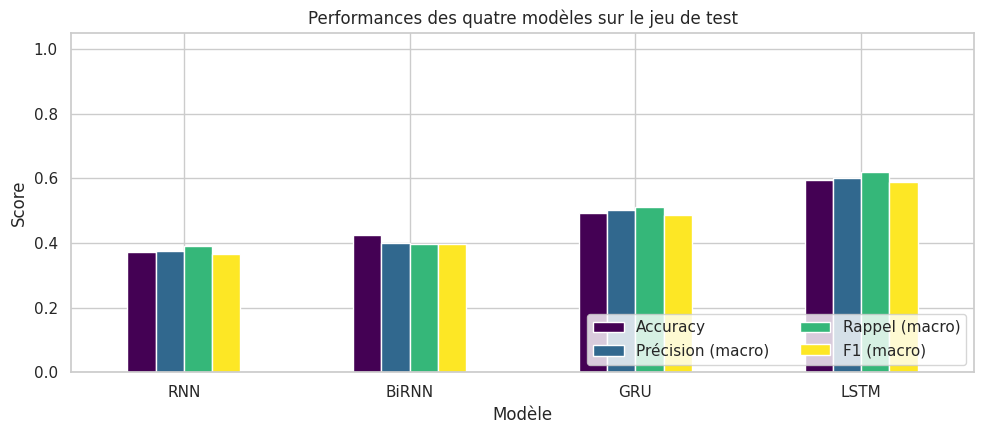

In [30]:
metrics_to_plot = ["Accuracy", "Précision (macro)", "Rappel (macro)", "F1 (macro)"]
df_results[metrics_to_plot].plot(kind="bar", figsize=(10, 4.5), rot=0, colormap="viridis", edgecolor="white")
plt.title("Performances des quatre modèles sur le jeu de test")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

### 10.2 Matrices de confusion

Chaque matrice indique, pour chaque classe réelle (lignes), la classe prédite (colonnes). La diagonale correspond aux prédictions correctes. Comme les classes sont ordonnées, on observe surtout si les erreurs se produisent entre classes voisines (acceptable) ou entre classes extrêmes (plus grave).

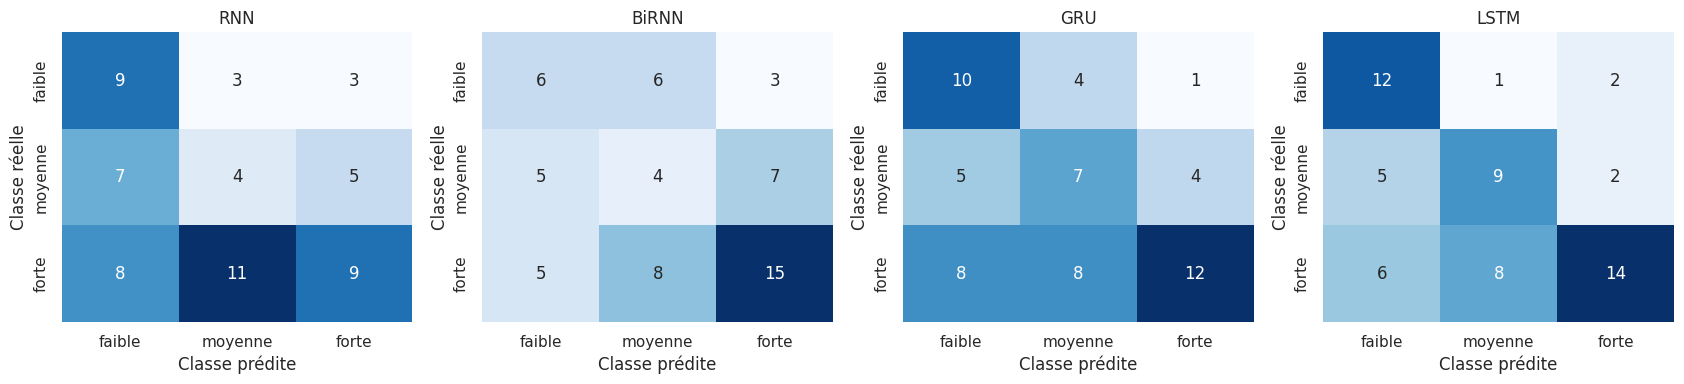

In [31]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, arch_name in zip(axes, ARCHITECTURES):
    y_true, y_pred = test_predictions[arch_name]
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(arch_name)
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")
plt.tight_layout()
plt.show()

**Remarque.** Pour le LSTM, la diagonale est la plus forte (12, 9 et 14). Il détecte bien la classe faible (12 sur 15). Les erreurs se font surtout entre classes voisines, ce qui est moins grave. Les trois autres modèles se trompent plus. Le RNN, par exemple, classe 11 textes « forte » comme « moyenne ». La classe « moyenne » est difficile pour tout le monde, ce qui est logique, car elle est au milieu et ses limites sont floues.

### 10.3 Rapports de classification détaillés

Les rapports donnent la précision, le rappel et le F1 de chaque classe pour chaque modèle (`support` = nombre de textes de la classe dans le test).

In [32]:
for arch_name in ARCHITECTURES:
    y_true, y_pred = test_predictions[arch_name]
    print(f"===== {arch_name} =====")
    print(classification_report(y_true, y_pred, labels=range(NUM_CLASSES),
                                target_names=CLASS_NAMES, zero_division=0, digits=3))

===== RNN =====
              precision    recall  f1-score   support

      faible      0.375     0.600     0.462        15
     moyenne      0.222     0.250     0.235        16
       forte      0.529     0.321     0.400        28

    accuracy                          0.373        59
   macro avg      0.376     0.390     0.366        59
weighted avg      0.407     0.373     0.371        59

===== BiRNN =====
              precision    recall  f1-score   support

      faible      0.375     0.400     0.387        15
     moyenne      0.222     0.250     0.235        16
       forte      0.600     0.536     0.566        28

    accuracy                          0.424        59
   macro avg      0.399     0.395     0.396        59
weighted avg      0.440     0.424     0.431        59

===== GRU =====
              precision    recall  f1-score   support

      faible      0.435     0.667     0.526        15
     moyenne      0.368     0.438     0.400        16
       forte      0.706  

## 11. Courbes d'apprentissage et analyse

### 11.1 Courbes de perte et de F1

Pour chaque architecture, on trace l'évolution de la perte et du F1 macro au fil des époques, pour l'entraînement et la validation. Un écart croissant entre les deux courbes signale un sur-apprentissage ; l'arrêt précoce conserve l'état du modèle à l'époque où la validation était la meilleure.

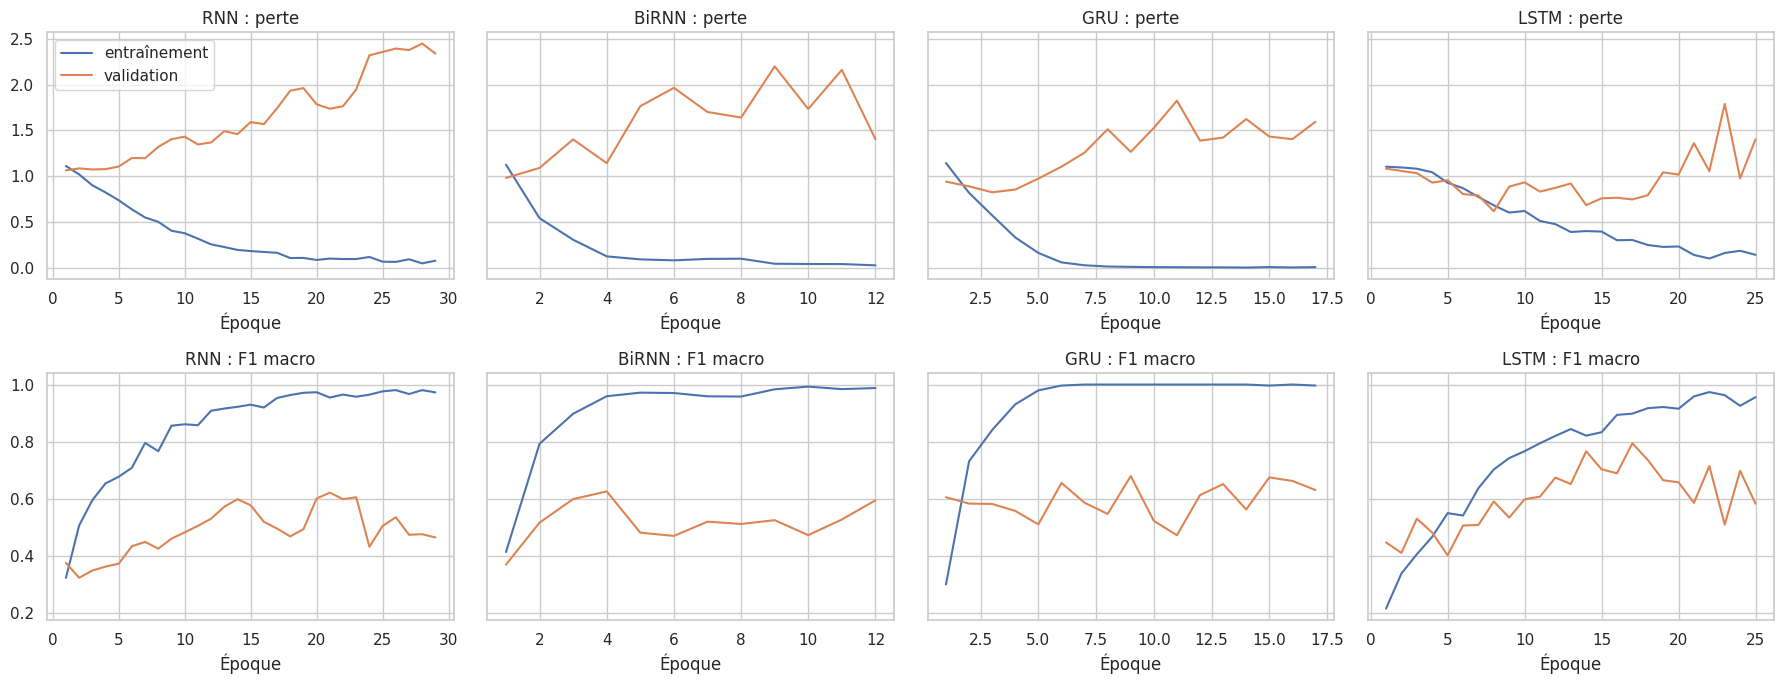

In [33]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey="row")
for j, arch_name in enumerate(ARCHITECTURES):
    h = best[arch_name]["history"]
    epochs = range(1, len(h["train_loss"]) + 1)

    axes[0, j].plot(epochs, h["train_loss"], label="entraînement")
    axes[0, j].plot(epochs, h["val_loss"], label="validation")
    axes[0, j].set_title(f"{arch_name} : perte")
    axes[0, j].set_xlabel("Époque")

    axes[1, j].plot(epochs, h["train_f1"], label="entraînement")
    axes[1, j].plot(epochs, h["val_f1"], label="validation")
    axes[1, j].set_title(f"{arch_name} : F1 macro")
    axes[1, j].set_xlabel("Époque")

axes[0, 0].legend()
plt.tight_layout()
plt.show()

**Remarque.** Les quatre modèles font du sur-apprentissage : le F1 du train monte vers 1, mais celui de la validation reste entre 0,5 et 0,8. Pour le RNN, le BiRNN et le GRU, la perte de validation augmente très tôt (dès les premières époques) alors que le F1 continue de bouger. On garde le meilleur modèle selon le F1 (pas selon la perte), donc le modèle gardé n'est pas forcément celui qui a la plus petite perte. Le LSTM apprend plus doucement et sa perte de validation descend jusqu'à l'époque 8 environ, ce qui explique en partie son meilleur résultat. Avec si peu de données, il faudrait plus de régularisation (dropout, weight decay) ou plus de textes.

### 11.2 Exemples de prédictions

On affiche quelques textes du test avec leur vraie classe et la classe prédite par le LSTM. Ça permet de comprendre un peu mieux où le modèle se trompe.

In [34]:
best_arch = df_results["F1 (macro)"].idxmax()
print("Meilleur modèle sur le test :", best_arch)

y_true_b, y_pred_b = test_predictions[best_arch]
test_df = df.iloc[test_idx].reset_index(drop=True)
test_df["pred"] = y_pred_b

# Quelques erreurs et quelques réussites
errors = test_df[test_df["label"] != test_df["pred"]].head(5)
correct = test_df[test_df["label"] == test_df["pred"]].head(3)

for title, subset in [("PRÉDICTIONS CORRECTES", correct), ("ERREURS", errors)]:
    print(f"\n===== {title} =====")
    for _, row in subset.iterrows():
        print(f"réel : {CLASS_NAMES[row['label']]:8s} | prédit : {CLASS_NAMES[row['pred']]:8s} | score : {row['Score']}")
        print("   ", row["Text"][:160].replace("\n", " "), "\n")

Meilleur modèle sur le test : LSTM

===== PRÉDICTIONS CORRECTES =====
réel : forte    | prédit : forte    | score : 9.0
    وزارة التربية الوطنية والتعليم الأولي والتكوين المهني والتأهيل هي الوزارة المخولة بتنظيم التعليم الأساسي في المملكة المغربية. == الاختصاصات == إعداد وتنفيذ سياس 

réel : forte    | prédit : forte    | score : 9.0
    الحياة المدرسية والتكوينات المشتركة بين الأكاديميات: قسم التقويم: مصلحة إعداد وتنظيم تقويم المتعلمين في التعليم الابتدائي مصلحة إعداد وتنظيم تقويم المتعلمين في  

réel : forte    | prédit : forte    | score : 9.0
    تعليم المواد العلمية والتربية البدنية قسم تعليم المواد التقنية والفنية قسم التعليم الأصيل المركز الوطني للتجديد التربوي و التجريب: قسم الارتقاء بالتكنولوجيات ال 


===== ERREURS =====
réel : forte    | prédit : moyenne  | score : 8.0
    جامعة ابن زهر هي جامعة مغربية عمومية أسِّست في عام 1989 بمدينة أكادير. يبلغ عدد طلبة وطالبات الجامعة حوالي 156,790، وتتكون هيئتها التدريسية من 1,475 أستاذا وأست 

réel : forte    | prédit : faible   | sco

## 12. Évaluation avec le score BLEU

Le TP demande d'évaluer les quatre modèles avec les métriques standard **et** avec le score BLEU. Le problème, c'est que le BLEU compare un texte généré avec un texte de référence : il ne s'applique pas à un classifieur qui donne seulement une classe.

Dans cette section, on fait donc travailler les quatre architectures (RNN, BiRNN, GRU, LSTM) sur une tâche de **génération de texte** : le modèle lit le début d'un texte (30 mots) et doit écrire la suite (20 mots). On compare sa suite avec la vraie suite grâce au BLEU. On calcule aussi la perplexité et l'accuracy sur les mots, qui sont les métriques standard pour ce genre de modèle.

On réutilise tout ce qui a été fait avant : le même dataset `df`, les mêmes fonctions de nettoyage et **la même séparation par article** (`train_idx`, `val_idx`, `test_idx`). Les variables de cette section commencent par `lm_` ou `LM_` pour ne pas écraser celles de la classification.

### 12.1 Données pour la génération

Pour la génération de texte, on **garde les mots vides** (contrairement à la classification) : un texte sans « في » ou « من » ne ressemblerait plus à de l'arabe. On utilise le même nettoyage qu'avant avec la normalisation des lettres, mais sans stemming ni lemmatisation. On importe aussi `nltk` pour le BLEU.

## 12. Sauvegarde des résultats et bilan

### 12.1 Sauvegarde

On enregistre les poids de chaque meilleur modèle, le vocabulaire, les hyperparamètres retenus et les paramètres de prétraitement. Ces éléments permettent de recharger un modèle sans refaire l'entraînement, et de documenter précisément l'expérience dans le rapport.

In [37]:
import itertools
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

# Mots de chaque texte : nettoyage + normalisation, mots vides conservés
df["words"] = df["Text"].apply(lambda t: normalize_arabic(clean_text(t)).split())

print("Mots par texte (moyenne) :", round(df["words"].str.len().mean(), 1))
print("Exemple :", " ".join(df["words"].iloc[0][:15]))
print("Textes : train", len(train_idx), "| validation", len(val_idx), "| test", len(test_idx))

Mots par texte (moyenne) : 106.5
Exemple : جامعه محمد الخامس هي جامعه مغربيه تاسست سنه بموجب ظهير ملكي شريف تقع وسط العاصمه
Textes : train 246 | validation 37 | test 59


### 12.2 Fenêtres et vocabulaire

#### 12.2.1 Début du texte et suite

Chaque texte est découpé en « fenêtres » de 50 mots :

- les **30 premiers mots** forment le début (la *source*, que le modèle lit) ;
- les **20 mots suivants** forment la suite (la *cible*, que le modèle doit écrire).

Pour le train, on fait glisser la fenêtre de 5 mots en 5 mots (`TRAIN_STRIDE`), ce qui donne beaucoup d'exemples à partir de peu de textes. Pour la validation et le test, on avance de 25 mots pour que les fenêtres se chevauchent peu.

In [38]:
PROMPT_LEN = 30
TARGET_LEN = 20
TRAIN_STRIDE = 5
EVAL_STRIDE = 25
WINDOW = PROMPT_LEN + TARGET_LEN

def build_windows(indices, stride):
    windows = []
    for i in indices:
        words = df["words"].iloc[i]
        for s in range(0, len(words) - WINDOW + 1, stride):
            windows.append(words[s:s + WINDOW])
    return windows

train_win = build_windows(train_idx, TRAIN_STRIDE)
val_win   = build_windows(val_idx, EVAL_STRIDE)
test_win  = build_windows(test_idx, EVAL_STRIDE)

print("Fenêtres : train", len(train_win), "| validation", len(val_win), "| test", len(test_win))

Fenêtres : train 2933 | validation 97 | test 165


#### 12.2.2 Vocabulaire

Comme avant, le vocabulaire est construit **uniquement avec les textes du train**. On ajoute trois mots spéciaux : `<pad>`, `<unk>` (mot inconnu) et `<bos>` (début de la phrase à générer). Les mots qui apparaissent moins de 2 fois deviennent `<unk>`.

In [39]:
LM_MIN_FREQ = 2
LM_PAD, LM_UNK, LM_BOS = "<pad>", "<unk>", "<bos>"

lm_counter = Counter(w for i in train_idx for w in df["words"].iloc[i])
lm_itos = [LM_PAD, LM_UNK, LM_BOS] + [w for w, c in lm_counter.most_common() if c >= LM_MIN_FREQ]
lm_stoi = {w: i for i, w in enumerate(lm_itos)}
PAD_ID, UNK_ID, BOS_ID = lm_stoi[LM_PAD], lm_stoi[LM_UNK], lm_stoi[LM_BOS]
LM_VOCAB_SIZE = len(lm_itos)

print("Mots distincts dans le train :", len(lm_counter))
print("Taille du vocabulaire :", LM_VOCAB_SIZE)

# Part des mots de la cible (test) qui sont inconnus du vocabulaire
test_targets = [w for win in test_win for w in win[PROMPT_LEN:]]
unk_rate = np.mean([w not in lm_stoi for w in test_targets])
print(f"Mots inconnus dans les cibles du test : {unk_rate:.1%}")

Mots distincts dans le train : 8024
Taille du vocabulaire : 3173
Mots inconnus dans les cibles du test : 38.8%


#### 12.2.3 Conversion en tenseurs

Chaque fenêtre devient trois tenseurs :

- `src` : les 30 mots du début (entrée de l'encodeur) ;
- `dec_in` : `<bos>` suivi des 19 premiers mots de la cible (entrée du décodeur pendant l'entraînement) ;
- `tgt` : les 20 mots de la cible (ce que le décodeur doit prédire).

On garde aussi les mots d'origine de la cible, car le BLEU se calcule sur les vrais mots et pas sur les indices.

In [40]:
def to_tensors(windows):
    src = torch.tensor([[lm_stoi.get(w, UNK_ID) for w in win[:PROMPT_LEN]] for win in windows])
    tgt = torch.tensor([[lm_stoi.get(w, UNK_ID) for w in win[PROMPT_LEN:]] for win in windows])
    bos = torch.full((len(windows), 1), BOS_ID, dtype=torch.long)
    dec_in = torch.cat([bos, tgt[:, :-1]], dim=1)
    return src, dec_in, tgt

train_t = to_tensors(train_win)
val_t   = to_tensors(val_win)
test_t  = to_tensors(test_win)

test_refs = [win[PROMPT_LEN:] for win in test_win]      # vraies suites (mots)
print("Formes (src, dec_in, tgt) :", [tuple(x.shape) for x in train_t])

def make_loader(tensors, batch_size, shuffle=False):
    return DataLoader(TensorDataset(*tensors), batch_size=batch_size, shuffle=shuffle)

Formes (src, dec_in, tgt) : [(2933, 30), (2933, 20), (2933, 20)]


### 12.3 Les modèles

#### 12.3.1 Pourquoi un encodeur - décodeur ?

Un modèle de langage « normal » prédit le mot suivant en lisant seulement les mots d'avant. Un **Bidirectional RNN ne peut pas faire ça** : il lit aussi les mots d'après, donc il verrait la réponse.

Pour pouvoir comparer les quatre architectures de façon juste, on utilise pour toutes la même structure :

```
début (30 mots) -> Embedding -> ENCODEUR [RNN | BiRNN | GRU | LSTM] -> état final
                                                                          |
<bos> + mots déjà écrits -> Embedding -> DÉCODEUR (même type, un seul sens) -> Linear -> mot suivant
```

L'encodeur lit le début du texte (il peut être bidirectionnel sans problème, car le début est connu). Son état final sert de point de départ au décodeur, qui écrit la suite mot par mot. Pour le BiRNN, une couche linéaire réunit les deux états (aller et retour) en un seul.

| Modèle | Encodeur | Décodeur |
|---|---|---|
| RNN | `nn.RNN` | `nn.RNN` |
| BiRNN | `nn.RNN` bidirectionnel | `nn.RNN` |
| GRU | `nn.GRU` | `nn.GRU` |
| LSTM | `nn.LSTM` | `nn.LSTM` |

In [42]:
class Seq2Seq(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, cell="LSTM",
                 bidirectional=False, dropout=0.3):
        super().__init__()
        self.cell = cell
        self.bidirectional = bidirectional
        rnn_cls = {"RNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}[cell]

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        self.drop = nn.Dropout(dropout)
        self.encoder = rnn_cls(embed_dim, hidden_dim, batch_first=True, bidirectional=bidirectional)
        self.decoder = rnn_cls(embed_dim, hidden_dim, batch_first=True)
        self.out = nn.Linear(hidden_dim, vocab_size)

        if bidirectional:   # réunit les états aller et retour en un seul état
            self.bridge_h = nn.Linear(2 * hidden_dim, hidden_dim)
            self.bridge_c = nn.Linear(2 * hidden_dim, hidden_dim)

    def _bridge(self, state, layer_name):
        if not self.bidirectional:
            return state                                       # un seul sens : rien à réunir
        layer = getattr(self, layer_name)                      # existe seulement si bidirectionnel
        both = torch.cat([state[0], state[1]], dim=1)          # (batch, 2*hidden)
        return torch.tanh(layer(both)).unsqueeze(0)            # (1, batch, hidden)

    def encode(self, src):
        _, state = self.encoder(self.drop(self.embedding(src)))
        if self.cell == "LSTM":
            return (self._bridge(state[0], "bridge_h"), self._bridge(state[1], "bridge_c"))
        return self._bridge(state, "bridge_h")

    def forward(self, src, dec_in):
        state = self.encode(src)
        out, _ = self.decoder(self.drop(self.embedding(dec_in)), state)
        return self.out(self.drop(out))                         # (batch, T, vocab)

    @torch.no_grad()
    def generate(self, src, steps):
        """Génère `steps` mots en prenant à chaque fois le mot le plus probable (greedy)."""
        self.eval()
        state = self.encode(src)
        token = torch.full((src.size(0), 1), BOS_ID, dtype=torch.long, device=src.device)
        generated = []
        for _ in range(steps):
            out, state = self.decoder(self.embedding(token), state)
            logits = self.out(out[:, -1])
            logits[:, [PAD_ID, UNK_ID, BOS_ID]] = -1e9          # on interdit les mots spéciaux
            token = logits.argmax(dim=1, keepdim=True)
            generated.append(token)
        return torch.cat(generated, dim=1)


LM_ARCHITECTURES = {
    "RNN":   {"cell": "RNN",  "bidirectional": False},
    "BiRNN": {"cell": "RNN",  "bidirectional": True},
    "GRU":   {"cell": "GRU",  "bidirectional": False},
    "LSTM":  {"cell": "LSTM", "bidirectional": False},
}

def lm_count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Test rapide : une passe avant et une génération pour chaque modèle
src_b, dec_b, tgt_b = [x[:4].to(device) for x in train_t]
for name, cfg in LM_ARCHITECTURES.items():
    m = Seq2Seq(LM_VOCAB_SIZE, 64, 64, **cfg).to(device)
    logits = m(src_b, dec_b)
    gen = m.generate(src_b, TARGET_LEN)
    print(f"{name:6s} | logits {tuple(logits.shape)} | génération {tuple(gen.shape)} | paramètres {lm_count_parameters(m):,}")

RNN    | logits (4, 20, 3173) | génération (4, 20) | paramètres 425,957
BiRNN  | logits (4, 20, 3173) | génération (4, 20) | paramètres 450,789
GRU    | logits (4, 20, 3173) | génération (4, 20) | paramètres 459,237
LSTM   | logits (4, 20, 3173) | génération (4, 20) | paramètres 475,877


### 12.4 Entraînement

#### 12.4.1 Fonctions d'entraînement

On entraîne avec le *teacher forcing* : pendant l'entraînement, le décodeur reçoit à chaque étape le **vrai** mot précédent (pas celui qu'il a prédit). La perte est l'entropie croisée sur les 20 mots de la cible. On garde le meilleur modèle selon la perte de validation et on arrête si elle ne baisse plus pendant 4 époques (*early stopping*).

In [43]:
def lm_run_epoch(model, loader, criterion, optimizer=None, clip=1.0):
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total_tokens = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for src, dec_in, tgt in loader:
            src, dec_in, tgt = src.to(device), dec_in.to(device), tgt.to(device)
            logits = model(src, dec_in)
            loss = criterion(logits.reshape(-1, LM_VOCAB_SIZE), tgt.reshape(-1))

            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), clip)
                optimizer.step()

            total_loss += loss.item() * tgt.numel()
            total_correct += (logits.argmax(dim=-1) == tgt).sum().item()
            total_tokens += tgt.numel()

    return total_loss / total_tokens, total_correct / total_tokens


def lm_fit(arch_cfg, hp, max_epochs=30, patience=4):
    set_seed(SEED)
    model = Seq2Seq(LM_VOCAB_SIZE, hp["embed_dim"], hp["hidden_dim"],
                    dropout=hp["dropout"], **arch_cfg).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=hp["lr"])
    train_loader = make_loader(train_t, hp["batch_size"], shuffle=True)
    val_loader = make_loader(val_t, 128)

    history = {"train_loss": [], "val_loss": []}
    best_loss, best_state, best_epoch, wait = np.inf, None, 0, 0
    start = time.time()

    for epoch in range(1, max_epochs + 1):
        tr_loss, _ = lm_run_epoch(model, train_loader, criterion, optimizer)
        va_loss, _ = lm_run_epoch(model, val_loader, criterion)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)

        if va_loss < best_loss:
            best_loss, best_epoch, wait = va_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return model, history, {"val_loss": best_loss, "best_epoch": best_epoch,
                            "train_time": time.time() - start}

#### 12.4.2 Choix des hyperparamètres

Ici le modèle est plus gros (la dernière couche prédit un mot parmi tout le vocabulaire), donc on fait une petite **recherche par grille** au lieu d'un grand tirage aléatoire : 2 tailles d'état caché × 2 taux d'apprentissage = 4 essais par modèle. L'embedding (128), le dropout (0,3) et la taille de batch (64) sont fixes. On compare avec la perte de validation.

In [44]:
FIXED_HP = {"embed_dim": 128, "dropout": 0.3, "batch_size": 64}
GRID = {"hidden_dim": [128, 256], "lr": [1e-3, 3e-3]}

lm_trial_hps = [{**FIXED_HP, **dict(zip(GRID.keys(), values))}
             for values in itertools.product(*GRID.values())]

lm_tune_rows, lm_best = [], {}
for arch_name, arch_cfg in LM_ARCHITECTURES.items():
    print(f"\n=== {arch_name} ===")
    for t, hp in enumerate(lm_trial_hps, start=1):
        model, history, info = lm_fit(arch_cfg, hp)
        lm_tune_rows.append({"architecture": arch_name, "hidden_dim": hp["hidden_dim"], "lr": hp["lr"],
                     "val_loss": info["val_loss"], "epoque": info["best_epoch"],
                     "temps (s)": info["train_time"]})
        print(f"essai {t}/{len(lm_trial_hps)} | hidden {hp['hidden_dim']:3d} | lr {hp['lr']} | "
              f"val loss {info['val_loss']:.3f} | epoque {info['best_epoch']}")
        if arch_name not in lm_best or info["val_loss"] < lm_best[arch_name]["info"]["val_loss"]:
            lm_best[arch_name] = {"model": model, "history": history, "hp": hp, "info": info}

lm_df_tuning = pd.DataFrame(lm_tune_rows)
lm_df_tuning.to_csv(os.path.join(OUT_DIR, "lm_tuning_results.csv"), index=False)
display(pd.DataFrame([{"architecture": a, **{k: lm_best[a]["hp"][k] for k in GRID},
                       "val_loss": round(lm_best[a]["info"]["val_loss"], 3),
                       "epoque": lm_best[a]["info"]["best_epoch"]} for a in LM_ARCHITECTURES]))


=== RNN ===
essai 1/4 | hidden 128 | lr 0.001 | val loss 4.953 | epoque 6
essai 2/4 | hidden 128 | lr 0.003 | val loss 5.027 | epoque 3
essai 3/4 | hidden 256 | lr 0.001 | val loss 4.986 | epoque 3
essai 4/4 | hidden 256 | lr 0.003 | val loss 5.068 | epoque 3

=== BiRNN ===
essai 1/4 | hidden 128 | lr 0.001 | val loss 4.959 | epoque 7
essai 2/4 | hidden 128 | lr 0.003 | val loss 5.023 | epoque 3
essai 3/4 | hidden 256 | lr 0.001 | val loss 4.994 | epoque 3
essai 4/4 | hidden 256 | lr 0.003 | val loss 5.047 | epoque 2

=== GRU ===
essai 1/4 | hidden 128 | lr 0.001 | val loss 4.950 | epoque 8
essai 2/4 | hidden 128 | lr 0.003 | val loss 4.999 | epoque 3
essai 3/4 | hidden 256 | lr 0.001 | val loss 4.961 | epoque 4
essai 4/4 | hidden 256 | lr 0.003 | val loss 5.005 | epoque 2

=== LSTM ===
essai 1/4 | hidden 128 | lr 0.001 | val loss 4.984 | epoque 11
essai 2/4 | hidden 128 | lr 0.003 | val loss 5.016 | epoque 3
essai 3/4 | hidden 256 | lr 0.001 | val loss 5.007 | epoque 5
essai 4/4 | hi

,architecture,hidden_dim,lr,val_loss,epoque
0,RNN,128,0.001,4.953,6
1,BiRNN,128,0.001,4.959,7
2,GRU,128,0.001,4.950,8
3,LSTM,128,0.001,4.984,11


#### 12.4.3 Courbes de perte

On trace la perte de train et de validation du meilleur essai de chaque modèle. Si la perte de validation remonte alors que celle du train descend, le modèle apprend les textes par cœur (sur-apprentissage).

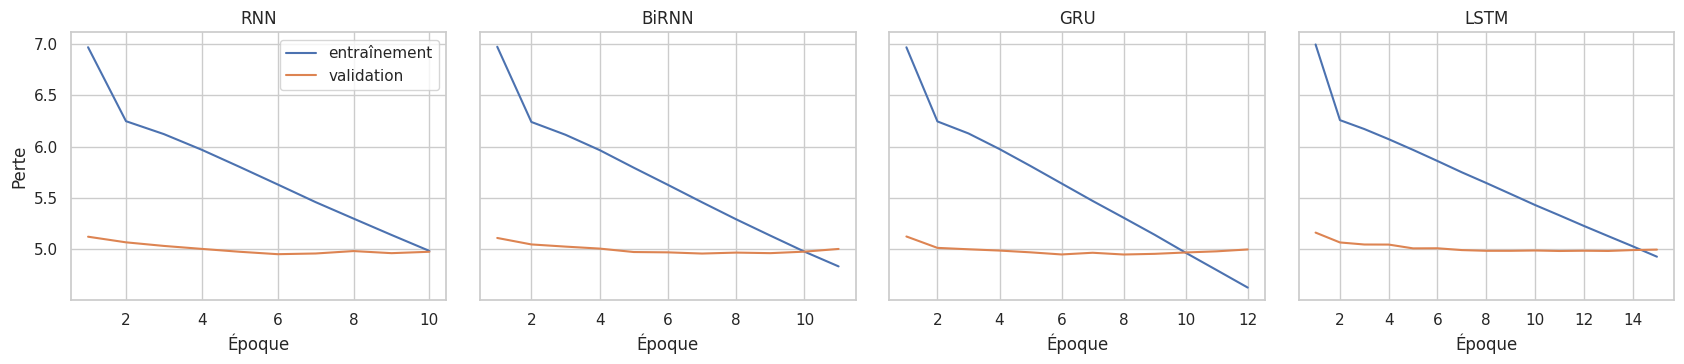

In [45]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for ax, arch_name in zip(axes, LM_ARCHITECTURES):
    h = lm_best[arch_name]["history"]
    ax.plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], label="entraînement")
    ax.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label="validation")
    ax.set_title(arch_name); ax.set_xlabel("Époque")
axes[0].set_ylabel("Perte"); axes[0].legend()
plt.tight_layout(); plt.show()

### 12.5 Évaluation sur le test

#### 12.5.1 Métriques standard : perplexité et accuracy

- **Perte** (entropie croisée) sur le test, avec le teacher forcing.
- **Perplexité** = exp(perte). Elle indique à peu près entre combien de mots le modèle hésite à chaque étape : plus elle est petite, mieux c'est.
- **Accuracy sur les mots** : pourcentage de mots prédits exactement comme dans le texte (avec le teacher forcing).

In [46]:
lm_test_loader = make_loader(test_t, 128)
criterion = nn.CrossEntropyLoss()

lm_rows = {}
for arch_name in LM_ARCHITECTURES:
    loss, acc = lm_run_epoch(lm_best[arch_name]["model"], lm_test_loader, criterion)
    lm_rows[arch_name] = {"Perte test": loss, "Perplexité": float(np.exp(loss)), "Accuracy mots": acc}

df_lm = pd.DataFrame(lm_rows).T
display(df_lm.round(3))

,Perte test,Perplexité,Accuracy mots
RNN,4.892,133.267,0.390
BiRNN,4.887,132.505,0.386
GRU,4.862,129.224,0.388
LSTM,4.906,135.095,0.389


#### 12.5.2 Génération et score BLEU

Pour le BLEU, on fait écrire la suite par chaque modèle : il lit les 30 mots du début et génère 20 mots en prenant à chaque étape le mot le plus probable (*greedy*). On compare ensuite avec la vraie suite.

Le **BLEU-n** mesure la proportion de séquences de n mots de la génération qui se trouvent aussi dans la référence :

- BLEU-1 : les mots isolés (est-ce que les bons mots sont utilisés ?)
- BLEU-2 : les paires de mots
- BLEU-4 : les groupes de 4 mots (est-ce que les phrases ressemblent à l'original ?)

On utilise `corpus_bleu` de NLTK avec un lissage (*smoothing*), sinon le score serait 0 dès qu'aucun groupe de 4 mots ne correspond. Les mots spéciaux (`<unk>`...) sont interdits dans la génération.

Comme point de comparaison, on ajoute une **référence minimale** : un « modèle » qui écrit toujours les 20 mots les plus fréquents du train. Un vrai modèle doit faire mieux que ça.

In [47]:
smooth = SmoothingFunction().method1

def compute_bleu(references, hypotheses):
    refs = [[r] for r in references]
    return {
        "BLEU-1": corpus_bleu(refs, hypotheses, weights=(1, 0, 0, 0), smoothing_function=smooth),
        "BLEU-2": corpus_bleu(refs, hypotheses, weights=(0.5, 0.5, 0, 0), smoothing_function=smooth),
        "BLEU-4": corpus_bleu(refs, hypotheses, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smooth),
    }

def generate_texts(model, src_tensor, batch_size=128):
    generated = []
    for i in range(0, len(src_tensor), batch_size):
        batch = src_tensor[i:i + batch_size].to(device)
        generated.append(model.generate(batch, TARGET_LEN).cpu())
    ids = torch.cat(generated).tolist()
    return [[lm_itos[t] for t in seq] for seq in ids]

generations = {}
bleu_rows = {}
for arch_name in LM_ARCHITECTURES:
    generations[arch_name] = generate_texts(lm_best[arch_name]["model"], test_t[0])
    bleu_rows[arch_name] = compute_bleu(test_refs, generations[arch_name])

# Référence minimale : toujours les mots les plus fréquents du train
frequent_words = [w for w, _ in lm_counter.most_common(TARGET_LEN)]
bleu_rows["Référence minimale"] = compute_bleu(test_refs, [frequent_words] * len(test_refs))

df_bleu = pd.DataFrame(bleu_rows).T
display(df_bleu.round(4))

,BLEU-1,BLEU-2,BLEU-4
RNN,0.0385,0.0111,0.0006
BiRNN,0.0494,0.0089,0.0006
GRU,0.0403,0.0113,0.0006
LSTM,0.0391,0.0112,0.0006
Référence minimale,0.1227,0.0153,0.0007


**Remarque.** Les scores BLEU sont très bas, et surtout **les quatre modèles font moins bien que la référence minimale** (liste fixe des 20 mots les plus fréquents) : BLEU-1 de 0,04 à 0,05 contre 0,12. Le BLEU-4 est presque nul pour tout le monde (0,0006), ce qui veut dire qu'aucun groupe de 4 mots n'est retrouvé. Le BiRNN a le meilleur BLEU-1 (0,049), mais la différence avec les autres est trop faible pour dire qu'il est meilleur. Ce résultat est honnête : avec si peu de données, des réseaux récurrents entraînés de zéro ne savent pas générer de l'arabe.

#### 12.5.3 Graphique de comparaison

Les barres comparent le BLEU-1, BLEU-2 et BLEU-4 des quatre modèles et de la référence minimale.

In [ ]:
df_bleu.plot(kind="bar", figsize=(9, 4.5), rot=0, colormap="viridis", edgecolor="white")
plt.title("Score BLEU sur le jeu de test")
plt.ylabel("BLEU")
plt.tight_layout(); plt.show()

### 12.6 Exemples de textes générés

On affiche quelques exemples du test : le début donné au modèle, la vraie suite et la suite générée par chaque modèle. C'est important de lire ces textes, parce que le BLEU seul ne dit pas si le texte est vraiment bon.

In [48]:
best_bleu_arch = df_bleu.loc[list(LM_ARCHITECTURES), "BLEU-1"].idxmax()
print("Modèle avec le meilleur BLEU-1 :", best_bleu_arch)

for k in [0, len(test_win) // 3, 2 * len(test_win) // 3]:
    print("\n" + "=" * 90)
    print("DÉBUT   :", " ".join(test_win[k][:PROMPT_LEN]))
    print("RÉEL    :", " ".join(test_refs[k]))
    for arch_name in LM_ARCHITECTURES:
        print(f"{arch_name:8s}:", " ".join(generations[arch_name][k]))

Modèle avec le meilleur BLEU-1 : BiRNN

DÉBUT   : جامعه ابن زهر هي جامعه مغربيه عموميه اسست في عام بمدينه اكادير يبلغ عدد طلبه وطالبات الجامعه حوالي وتتكون هيئتها التدريسيه من استاذا واستاذا مساعدا وباحثا تعتبر جامعه ابن زهر
RÉEL    : اكبر جامعه بالمغرب فهي تغطي ازيد من من التراب الوطني وتضم شبكه واسعه من المؤسسات الجامعيه كما يتوافد اليها الطلبه
RNN     : في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب
BiRNN   : في المغرب من قبل الشرطه من قبل الشرطه من قبل الشرطه من قبل الشرطه من قبل الشرطه من قبل الشرطه
GRU     : في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب
LSTM    : في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب في المغرب

DÉBUT   : العامه مديريه التعليم العالي والتنميه البيداغوجيه مديريه البحث العلمي والابتكار مديريه الاستراتيجيات والنظم المعلوماتيه مديريه الشؤون القانونيه والمعادلات والمنازعات مديريه الميزانيه والشؤون العامه مديريه ا

**Remarque.** La lecture des textes explique les chiffres : les quatre modèles tombent dans une **boucle** et répètent les mêmes expressions (« في المغرب » pour le RNN, le GRU et le LSTM, « من قبل الشرطه » pour le BiRNN), quel que soit le début du texte. Ils ont appris les expressions les plus fréquentes du train et ne tiennent pas compte du début donné. Le décodage *greedy* aggrave ce problème. Il manque simplement de données : 2 933 fenêtres d'entraînement pour un vocabulaire de 3 173 mots.

### 12.7 Synthèse classification et génération

On rassemble dans un seul tableau les résultats des deux tâches : la classification (sections 5 à 11, tableau `df_results`) et la génération de texte (cette section).

In [49]:
df_cls = df_results[["Accuracy", "F1 (macro)"]].copy()
df_cls.columns = ["Classif. Accuracy", "Classif. F1 macro"]

final_summary = pd.concat([df_cls, df_lm, df_bleu.loc[list(LM_ARCHITECTURES)]], axis=1)
display(final_summary.round(3))
final_summary.to_csv(os.path.join(OUT_DIR, "synthese_classification_et_generation.csv"))

,Classif. Accuracy,Classif. F1 macro,Perte test,Perplexité,Accuracy mots,BLEU-1,BLEU-2,BLEU-4
RNN,0.373,0.366,4.892,133.267,0.390,0.038,0.011,0.001
BiRNN,0.424,0.396,4.887,132.505,0.386,0.049,0.009,0.001
GRU,0.492,0.487,4.862,129.224,0.388,0.040,0.011,0.001
LSTM,0.593,0.590,4.906,135.095,0.389,0.039,0.011,0.001


**Remarque.** Le tableau montre deux situations différentes. En **classification**, les modèles sont bien séparés (le LSTM est le meilleur avec 0,59 de F1). En **génération**, les quatre modèles sont presque identiques, et aucun n'est bon. Pour classer un texte, quelques mots-clés suffisent, alors que pour en écrire un il faut apprendre la langue elle-même, ce qui demande beaucoup plus de données. C'est une bonne raison de passer à la partie 2 : GPT-2 a déjà appris l'arabe sur un très grand corpus, et on a seulement besoin de l'adapter à notre sujet.

### 12.8 Sauvegarde des modèles de génération

On enregistre les modèles de génération, le vocabulaire et les résultats.

In [50]:
for arch_name in LM_ARCHITECTURES:
    torch.save(lm_best[arch_name]["model"].state_dict(), os.path.join(OUT_DIR, f"lm_{arch_name}.pt"))

with open(os.path.join(OUT_DIR, "lm_vocab.json"), "w", encoding="utf-8") as f:
    json.dump(lm_itos, f, ensure_ascii=False)

df_bleu.to_csv(os.path.join(OUT_DIR, "bleu_results.csv"))
df_lm.to_csv(os.path.join(OUT_DIR, "lm_test_results.csv"))
print("Fichiers enregistrés dans :", OUT_DIR)

Fichiers enregistrés dans : /content/drive/MyDrive/Projet_NLP_Education_Maroc/resultats_partie1


#### Limites de cette section

- Le corpus est très petit (quelques centaines de textes). Les modèles apprennent surtout à répéter des mots fréquents et des expressions du domaine : on ne peut pas s'attendre à un texte arabe vraiment cohérent.
- Le BLEU est calculé avec une seule référence par exemple, alors qu'il existe plein de suites correctes possibles. Les scores sont donc forcément bas, même pour un bon modèle.
- Les phrases générées en mode *greedy* ont tendance à se répéter.
- Un seul entraînement par modèle (une seule graine) et un test de taille modeste : les petits écarts entre modèles ne sont pas forcément significatifs.
- La partie 2 du TP (GPT-2 fine-tuné) permettra de comparer avec un modèle pré-entraîné beaucoup plus puissant.

## 13. Sauvegarde et bilan

### 13.1 Sauvegarde

On enregistre les poids des 4 modèles, le vocabulaire et les paramètres choisis (prétraitement, hyperparamètres...). Comme ça, on peut recharger un modèle sans refaire l'entraînement.

In [51]:
for arch_name in ARCHITECTURES:
    torch.save(best[arch_name]["model"].state_dict(), os.path.join(OUT_DIR, f"model_{arch_name}.pt"))

with open(os.path.join(OUT_DIR, "vocab.json"), "w", encoding="utf-8") as f:
    json.dump(itos, f, ensure_ascii=False)

config = {
    "preprocessing": PREPROC_MODE,
    "bins": BINS, "classes": CLASS_NAMES,
    "min_freq": MIN_FREQ, "max_len": MAX_LEN, "vocab_size": VOCAB_SIZE,
    "split_seed": int(best_seed), "seed": SEED,
    "n_trials": N_TRIALS,
    "best_hyperparameters": {a: {k: (float(v) if isinstance(v, float) else int(v))
                                 for k, v in best[a]["hp"].items()} for a in ARCHITECTURES},
}
with open(os.path.join(OUT_DIR, "config.json"), "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("Fichiers enregistrés dans :", OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))

Fichiers enregistrés dans : /content/drive/MyDrive/Projet_NLP_Education_Maroc/resultats_partie1
['bleu_results.csv', 'config.json', 'dataset_preprocessed.csv', 'lm_BiRNN.pt', 'lm_GRU.pt', 'lm_LSTM.pt', 'lm_RNN.pt', 'lm_test_results.csv', 'lm_tuning_results.csv', 'lm_vocab.json', 'model_BiRNN.pt', 'model_GRU.pt', 'model_LSTM.pt', 'model_RNN.pt', 'synthese_classification_et_generation.csv', 'test_results.csv', 'tuning_results.csv', 'vocab.json']


### 13.2 Bilan

**Ce qu'on a fait**

- Transformation du score en 3 classes.
- Prétraitement NLP complet (nettoyage, tokenisation, mots vides, stemming, lemmatisation, normalisation).
- Séparation train / validation / test par article.
- Entraînement de RNN, BiRNN, GRU et LSTM avec recherche aléatoire d'hyperparamètres.
- Évaluation avec accuracy, précision, rappel, F1, MAE et matrices de confusion.
- Évaluation des mêmes architectures sur une tâche de génération de texte, avec perplexité, accuracy sur les mots et score BLEU (section 12).

**Résultats sur le test** (59 textes)

| Modèle | Accuracy | F1 macro |
|---|---|---|
| RNN | 0,373 | 0,366 |
| BiRNN | 0,424 | 0,396 |
| GRU | 0,492 | 0,487 |
| LSTM | 0,593 | 0,590 |

Le LSTM est le meilleur, suivi du GRU, puis du BiRNN et du RNN simple. C'est cohérent avec la théorie : le LSTM et le GRU ont des portes qui gardent mieux l'information sur des textes longs, alors que le RNN simple oublie vite. Un hasard donnerait environ 33 % (3 classes), donc le RNN et le BiRNN sont à peine meilleurs que ça.

**Résultats de la génération de texte** (section 12)

| Modèle | Perplexité | BLEU-1 | BLEU-4 |
|---|---|---|---|
| RNN | 133,3 | 0,039 | 0,0006 |
| BiRNN | 132,5 | 0,049 | 0,0006 |
| GRU | 129,2 | 0,040 | 0,0006 |
| LSTM | 135,1 | 0,039 | 0,0006 |
| Référence minimale (mots fréquents) | - | 0,123 | 0,0007 |

Les quatre modèles ont des résultats presque identiques et restent **en dessous de la référence minimale** : ils répètent des expressions fréquentes sans tenir compte du début du texte. Le classement vu en classification (LSTM > GRU > BiRNN > RNN) ne se retrouve donc pas en génération.

**Limites**

- Le dataset est petit (342 textes). Le test n'a que 59 textes, donc un seul texte change l'accuracy d'environ 1,7 point. Les écarts entre GRU et BiRNN, par exemple, ne sont pas très fiables.
- On a fait un seul entraînement par modèle, sans répéter avec d'autres graines. Les résultats peuvent changer d'une exécution à l'autre.
- Tous les modèles font du sur-apprentissage : F1 proche de 1 sur le train, mais autour de 0,6 sur la validation.
- Le F1 de validation du LSTM (0,795) est bien plus haut que son F1 de test (0,590). Cela s'explique par la validation de seulement 37 textes et par le fait qu'on a pris le meilleur de 12 essais.
- Les erreurs de stemming et de lemmatisation en arabe peuvent aussi gêner un peu les modèles.
- En génération, 38,8 % des mots de la cible du test sont inconnus du vocabulaire : l'accuracy sur les mots est donc trompeuse, et le BLEU reste très bas.
- Le score a été construit en partie avec des mots-clés sur l'éducation, donc un modèle peut juste apprendre à repérer ces mots.

